In [2]:
from langgraph.graph import StateGraph,START,END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser,PydanticOutputParser
from typing import TypedDict,Optional,Literal
from pydantic import BaseModel,Field

In [3]:
load_dotenv()

True

In [4]:
llm=ChatOpenAI(model='gpt-4o')

In [5]:
str_parser=StrOutputParser()

In [6]:
class QueryState(TypedDict):
    query:str
    query_type:str
    response:str

In [7]:
class QuerySchema(BaseModel):
    query_type:Literal['ORDER','PAYMENT',"OTHER"] = Field(description='type of the user query')

In [8]:
query_parser=PydanticOutputParser(pydantic_object=QuerySchema)

In [9]:
def classify_query(state:QueryState):
    
    template = """
    You are an intent classification assistant for an E-Commerce and
    Quick-Commerce platform.

    Your task is to classify the user's query into exactly ONE of these
    three query types:

    1. ORDER
    Use this category when the user asks about placing, tracking,
    modifying, cancelling, returning, or managing an order.

    Examples:
    - Where is my order?
    - I want to cancel my order.
    - Add two more items to my order.
    - My delivery is delayed.
    - Can I return the product I purchased?

    2. PAYMENT
    Use this category when the user asks about payments, refunds,
    billing, transaction failures, payment methods, or payment status.

    Examples:
    - My payment failed.
    - I want a refund for my payment.
    - Was I charged twice?
    - Can I pay using UPI?
    - My money was deducted but the order was not placed.

    3. OTHER
    Use this category for queries that do not primarily concern
    orders or payments.

    Examples:
    - What is your return policy?
    - Do you sell organic vegetables?
    - What are your delivery charges?
    - I want to know about a product.
    - Hello, how are you?

    Classification rules:
    - Return exactly one category: ORDER, PAYMENT, or OTHER.
    - Classify based on the user's primary intent.
    - If a query mentions both an order and a payment, classify it
    according to the main issue the user wants to resolve.
    - General product inquiries, greetings, recommendations, and
    platform-related questions should be classified as OTHER.
    - Do not answer the user's query.
    - Do not invent additional categories.

    User query:
    {query}

    {format_instructions}
    """

    prompt = PromptTemplate(
        template=template,
        input_variables=["query"],
        partial_variables={
            "format_instructions": query_parser.get_format_instructions()
        }
    )

    chain = prompt | llm | query_parser
    response= chain.invoke({'query':state['query']})
    return {'query_type':response.query_type}


In [10]:
def generate_order_feedback(state:QueryState):
    order_feedback_template = """You are a friendly and caring customer support assistant for an
    E-Commerce and Quick-Commerce platform.

    Your task is to generate a sweet, empathetic, and reassuring response
    to a customer's order-related query.

    Customer query:
    {query}

    Instructions:
    1. Acknowledge the customer's concern politely.
    2. Show empathy and make the customer feel valued.
    3. Reassure the customer that the order-related issue will be
    addressed and resolved within the next 2 hours.
    4. Use simple, natural, warm, and professional language.
    5. Keep the response short, ideally 2-3 sentences.
    6. Avoid technical terms, unnecessary details, and robotic language.
    7. Do not answer the original query or invent order details.
    8. Do not include greetings or sign-offs unless necessary.
    9. Return only the customer-facing response.

    Generate the response:
    """

    prompt= PromptTemplate(template=order_feedback_template,input_variables=['query'])
    chain= prompt | llm | str_parser
    response= chain.invoke({'query':state['query']})
    return {'response':response}


In [11]:
def generate_payment_feedback(state:QueryState):
    payment_feedback_template = """
    You are a friendly, caring, and professional customer support
    assistant for an E-Commerce and Quick-Commerce platform.

    Your task is to generate a sweet, empathetic, and reassuring
    response to a customer's payment-related query.

    Customer query:
    {query}

    Instructions:
    1. Acknowledge the customer's payment concern politely.
    2. Express empathy and make the customer feel valued.
    3. Reassure the customer that the payment-related issue will be
    addressed and resolved within the next 2 days.
    4. Use warm, sweet, natural, and professional language.
    5. Keep the response concise, ideally 2-3 sentences.
    6. You may use an appropriate emoji to make the response friendly.
    7. Do not claim that a refund has been initiated or completed
    unless this information is explicitly provided.
    8. Do not invent transaction details or payment status.
    9. Do not answer questions about the actual transaction.
    10. Return only the customer-facing response.

    Generate the response:
    """

    prompt= PromptTemplate(template=payment_feedback_template,input_variables=['query'])
    chain= prompt | llm | str_parser
    response= chain.invoke({'query':state['query']})
    return {'response':response}

In [12]:
def generate_other_feedback(state:QueryState):

    other_feedback_template = """
    You are a friendly, caring, and professional customer support
    assistant for an E-Commerce and Quick-Commerce platform.

    Your task is to generate a sweet and polite response to a
    customer's general query that is not related to orders or payments.

    Customer query:
    {query}

    Instructions:
    1. Thank the customer for reaching out to us.
    2. Acknowledge their query politely.
    3. Reassure them that our support team will contact them soon
    to assist with their query.
    4. Use warm, friendly, empathetic, and professional language.
    5. Keep the response concise, ideally 2-3 sentences.
    6. You may use an appropriate emoji to make the response friendly.
    7. Do not answer the customer's original query.
    8. Do not invent specific contact times or promise a resolution.
    9. Return only the customer-facing response.

    Generate the response:
    """
    prompt= PromptTemplate(template=other_feedback_template,input_variables=['query'])
    chain= prompt | llm | str_parser
    response= chain.invoke({'query':state['query']})
    return {'response':response}



In [18]:
def query_check(state:QueryState) -> Literal['generate_order_feedback','generate_payment_feedback','generate_other_feedback']:
    query_type=state['query_type']
    if query_type.upper()== 'ORDER':
        return 'generate_order_feedback'
    elif query_type.upper() == 'PAYMENT':
        return 'generate_payment_feedback'
    return 'generate_other_feedback'

In [19]:
graph= StateGraph(QueryState)


In [20]:
# Add Nodes

graph.add_node('generate_order_feedback',generate_order_feedback)
graph.add_node('generate_payment_feedback',generate_payment_feedback)
graph.add_node('generate_other_feedback',generate_other_feedback)
graph.add_node('classify_query',classify_query)


graph.add_edge(START,'classify_query')
graph.add_conditional_edges('classify_query',query_check)
graph.add_edge('generate_order_feedback',END)
graph.add_edge('generate_payment_feedback',END)
graph.add_edge('generate_other_feedback',END)

In [21]:
workflow=graph.compile()

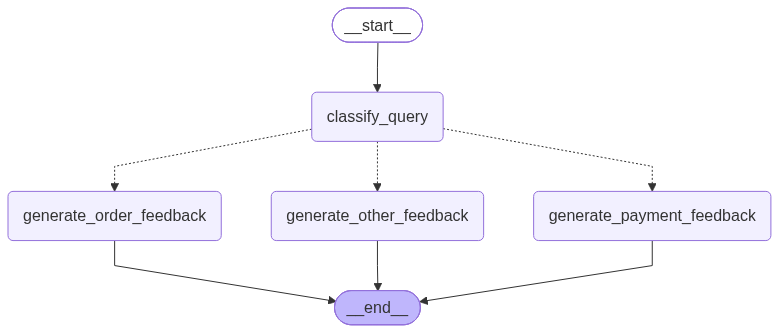

In [22]:
workflow

In [31]:
# query= "My order has not been delivered yet, even though the expected delivery date has passed."
# query= """My money was deducted from my bank account, but I have not received a refund."""
query= """Do you offer any special discounts on bulk purchases?"""

In [32]:
initial_state={'query':query}

In [33]:
final_state= workflow.invoke(initial_state)

In [34]:
final_state

{'query': 'Do you offer any special discounts on bulk purchases?',
 'query_type': 'OTHER',
 'response': 'Thank you so much for reaching out to us! 😊 We truly appreciate your interest in our offerings. Our dedicated support team will be in touch with you shortly to assist further. Have a wonderful day!'}